# MS11 — Détection d'anomalies · Notebook 04 (CRISP-DM)

**Objectif métier.** Repérer automatiquement les **trajets anormaux** (incidents) pour alerter l'administration.

**Dataset propre à MS11** (`data/anomaly_dataset.csv`) avec des **anomalies hétérogènes et contextuelles** :
- **franc** (panne/accident) : durée énorme → ratio très élevé (facile) ;
- **contextuel** : ratio modéré MAIS par conditions légères (fluide) → anormal *vu le contexte* ;
- **surcharge** : durée quasi normale mais montées/descentes anormales.

**Thèse du notebook.** Aucune variable seule ne capte les 3 natures → il faut **du feature engineering**
(`surprise` = ratio ajusté au contexte) **et** un détecteur **multivarié curé** (Isolation Forest).
Modèle **non supervisé** ; le label `incident_type` sert **uniquement à évaluer**.

**Étape 0 — Environnement.**

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
while os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("notebooks/figures", exist_ok=True)
FIG = "notebooks/figures"
from config import settings
print("Répertoire de travail :", os.getcwd())

Répertoire de travail : C:\Users\Anass\Desktop\SDIA\S9\PFE\transport-scolaire\ms11-analytique


**Étape 1 — Données.** On génère le dataset d'anomalies s'il n'existe pas, puis on le charge.

In [2]:
from features import label_binaire, build, CURATED, colonnes_all
if not os.path.exists(settings.dataset_path):
    import dataset_anomaly
    dataset_anomaly.generer().to_csv(settings.dataset_path, index=False)
df = pd.read_csv(settings.dataset_path)
y = label_binaire(df)
print("Trajets :", len(df), "| incidents :", int(y.sum()), f"({100*y.mean():.2f}%)")
print(df["incident_type"].value_counts())

Trajets : 4320 | incidents : 54 (1.25%)
incident_type
none                 4266
retard_contextuel      22
accident                9
route_bloquee           9
panne                   7
surcharge               7
Name: count, dtype: int64


**Étape 2 — EDA : `ratio` vs `surprise`.** Le `ratio` brut ne sépare pas les anomalies **contextuelles** (elles ressemblent à un trajet de trafic dense). La `surprise` (= ratio ajusté au contexte) les fait ressortir.

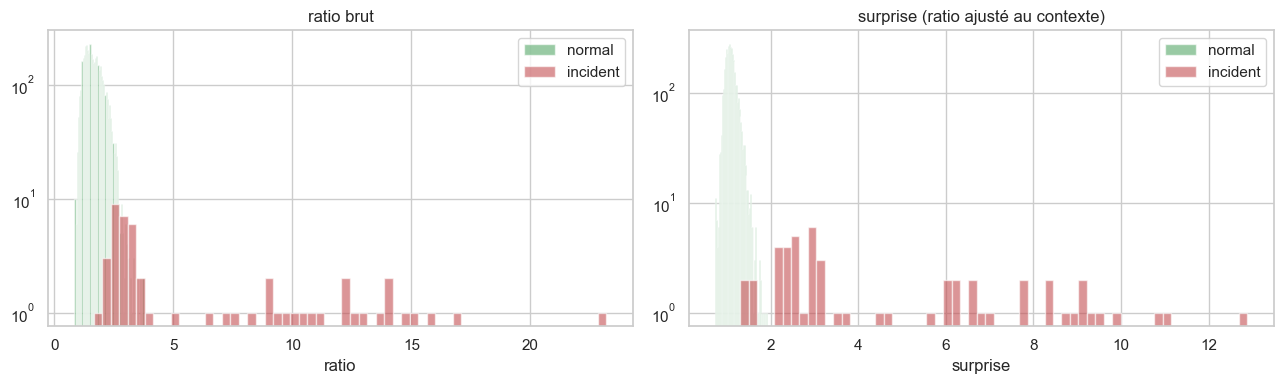

In [3]:
F = build(df)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for lab, col, name in [(0, "#55a868", "normal"), (1, "#c44e52", "incident")]:
    ax[0].hist(F["ratio"][y == lab], bins=60, alpha=.6, label=name, color=col)
    ax[1].hist(F["surprise"][y == lab], bins=60, alpha=.6, label=name, color=col)
ax[0].set_yscale("log"); ax[0].set_title("ratio brut"); ax[0].set_xlabel("ratio"); ax[0].legend()
ax[1].set_yscale("log"); ax[1].set_title("surprise (ratio ajusté au contexte)"); ax[1].set_xlabel("surprise"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/04_ratio_vs_surprise.png", dpi=110, bbox_inches="tight"); plt.show()

**Étape 3 — Benchmark de 4 détecteurs.** 2 seuils univariés (ratio, surprise) vs 2 Isolation Forest (toutes features = *dilué*, features *curées*). Split temporel, évaluation à budget d'alerte fixe.

In [4]:
from train_anomaly import _split_temporel, _evaluer
from anomaly import AnomalyDetector

train, test = _split_temporel(df)
ytr, yte = label_binaire(train), label_binaire(test)
contam = float(min(0.2, max(0.01, ytr.mean())))
cols_all = colonnes_all(df)

detecteurs = {
    "seuil_ratio":     AnomalyDetector("seuil_ratio", "threshold", contam, threshold_col="ratio"),
    "seuil_surprise":  AnomalyDetector("seuil_surprise", "threshold", contam, threshold_col="surprise"),
    "iforest_all":     AnomalyDetector("iforest_all", "iforest", contam, settings.seed, feature_cols=cols_all),
    "iforest_curated": AnomalyDetector("iforest_curated", "iforest", contam, settings.seed, feature_cols=CURATED),
}
scores_test, rows = {}, []
for nom, det in detecteurs.items():
    det.fit(train); s = det.scores(test); scores_test[nom] = s
    pred = s >= np.quantile(s, 1 - contam)
    m = _evaluer(yte.to_numpy(), s, pred)
    rows.append({"detecteur": nom, "PR_AUC": m["PR_AUC"], "ROC_AUC": m["ROC_AUC"],
                 "F1": m["F1"], "precision": m["precision"], "rappel": m["rappel"]})
res = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
res

,detecteur,PR_AUC,ROC_AUC,F1,precision,rappel
0,iforest_curated,0.9127,0.9988,0.7778,0.7000,0.875
1,seuil_surprise,0.8043,0.9867,0.6316,0.5455,0.750
2,seuil_ratio,0.7934,0.9407,0.6667,0.6000,0.750
3,iforest_all,0.4818,0.9754,0.4444,0.4000,0.500


**Étape 4 — Courbes ROC & Précision-Rappel.**

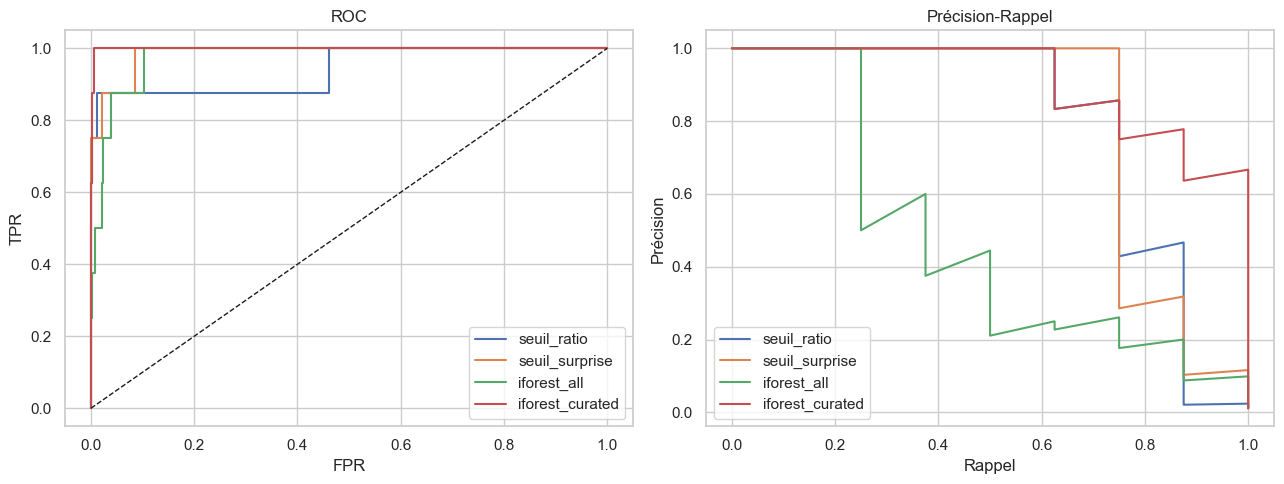

In [5]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nom, s in scores_test.items():
    fpr, tpr, _ = roc_curve(yte, s); ax[0].plot(fpr, tpr, label=nom)
    prec, rec, _ = precision_recall_curve(yte, s); ax[1].plot(rec, prec, label=nom)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
ax[1].set_title("Précision-Rappel"); ax[1].set_xlabel("Rappel"); ax[1].set_ylabel("Précision"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/04_courbes_roc_pr.png", dpi=110, bbox_inches="tight"); plt.show()

**Étape 5 — Matrice de confusion du gagnant** (budget d'alerte fixe).

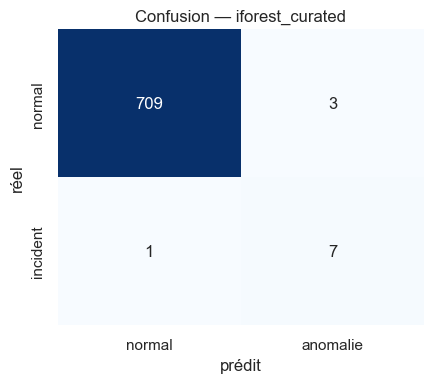

Gagnant : iforest_curated


In [6]:
from sklearn.metrics import confusion_matrix
best = res.iloc[0]["detecteur"]; s = scores_test[best]
pred = s >= np.quantile(s, 1 - contam)
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["normal", "anomalie"], yticklabels=["normal", "incident"], ax=ax)
ax.set_title(f"Confusion — {best}"); ax.set_xlabel("prédit"); ax.set_ylabel("réel")
plt.tight_layout(); plt.savefig(f"{FIG}/04_confusion.png", dpi=110, bbox_inches="tight"); plt.show()
print("Gagnant :", best)

**Étape 6 — Interprétation (honnête, triple leçon).**
1. **Le feature engineering prime** : `surprise` (contextuel) sépare mieux que le `ratio` brut.
2. **La curation prime** : `iforest_curated` ≫ `iforest_all` — trop de features **diluent** le signal (Isolation
   Forest traite toutes les dimensions à égalité).
3. **Le multivarié gagne ICI** parce que les anomalies sont **hétérogènes** (franc + contextuel + surcharge) :
   aucun seuil univarié ne les capte toutes ; le détecteur curé les combine.

**Étape 7 — Gel du modèle de production** (benchmark → gagnant → réentraînement sur tout → artefacts).

In [7]:
import train_anomaly
train_anomaly.main()
cfg = json.load(open(settings.config_path, encoding="utf-8"))
print(json.dumps({k: cfg[k] for k in ["detecteur","kind","feature_cols","threshold","contamination","metrics_test","taux_incidents_%"]},
                 indent=2, ensure_ascii=False))

[MS11] 4320 trajets | train=3600 test=720 | incidents train=1.28% | contamination=0.013
  seuil_ratio        PR-AUC=0.793 ROC-AUC=0.941 F1=0.667 (P=0.60 R=0.75)
  seuil_surprise     PR-AUC=0.804 ROC-AUC=0.987 F1=0.632 (P=0.55 R=0.75)


  iforest_all        PR-AUC=0.482 ROC-AUC=0.975 F1=0.444 (P=0.40 R=0.50)


  iforest_curated    PR-AUC=0.913 ROC-AUC=0.999 F1=0.778 (P=0.70 R=0.88)

[MS11] 🏆 Gagnant : iforest_curated


[MS11] Artefacts : data/anomaly_model.pkl | data/anomaly_config.json | data/anomaly_benchmark.json
{
  "detecteur": "iforest_curated",
  "kind": "iforest",
  "feature_cols": [
    "surprise",
    "ratio",
    "dwell",
    "nb_montees",
    "nb_descentes",
    "taux_occupation"
  ],
  "threshold": 0.6145276552899578,
  "contamination": 0.012777777777777779,
  "metrics_test": {
    "ROC_AUC": 0.9988,
    "PR_AUC": 0.9127,
    "precision": 0.7,
    "rappel": 0.875,
    "F1": 0.7778,
    "confusion": [
      [
        709,
        3
      ],
      [
        1,
        7
      ]
    ]
  },
  "taux_incidents_%": 1.25
}


### Conclusion
- Détecteur gelé (`anomaly_model.pkl`) servi par **MS11** (`POST /api/analytique/anomalies`, `GET .../scan`).
- Boucle DS : les incidents que l'**ETA (MS12)** ne peut pas prédire sont ceux que la **détection
  d'anomalies (MS11)** isole — grâce au feature engineering contextuel et à un modèle multivarié curé.